## Análises estatísticas do quarto lote de testes (Lote 4 - BMSSP-Opt Reescrito)

Neste quarto lote de testes (Lote 4), avaliamos os quatro algoritmos com a reescrita de alta performance do BMSSP-Opt (`graphs/duan_et_al_opt.py`), implementada com arrays indexados, relaxamento inline e `BatchPQOpt`:
1. **Dijkstra** (baseline de referência)
2. **SSSP (Duan et al. - Recursivo)**: implementação recursiva canônica.
3. **SSSP (Duan et al. - Iterativo)**: implementação iterativa com pilha explícita (`_Frame`).
4. **SSSP (Duan et al. - Otimizado)**: implementação reescrita com arrays contíguos e relaxamento inline.

Os testes foram executados sobre os grafos salvos do Lote 3, cobrindo instâncias sintéticas $G(n, p)$ (10k, 50k, 100k vértices) e redes viárias reais DIMACS (USA Road Networks), com e sem redução de grau.

In [4]:
# importando bibliotecas e carregando os dados do lote 4
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np

random_test = pd.read_csv('../data/lote4-tcc2/results/results-2026-10-25_00-27-26.csv')
random_test_transformed = pd.read_csv('../data/lote4-tcc2/results/results-2026-10-24_22-36-20.csv')

dimacs_test = pd.read_csv('../data/lote4-tcc2/results/dimacs-results-2026-10-25_03-00-21.csv')
dimacs_test_transformed = pd.read_csv('../data/lote4-tcc2/results/dimacs-results-2026-10-25_02-14-33.csv')

#### 1. Avaliação de Corretude (is_correct e error_count)

In [5]:
# Tabela consolidada da taxa de acerto por experimento e algoritmo
def resumo_corretude(df, nome_experimento):
    res = df.groupby('algorithm').agg(
        total_execucoes=('is_correct', 'count'),
        execucoes_corretas=('is_correct', lambda x: x.sum()),
        taxa_acerto=('is_correct', lambda x: f"{x.mean()*100:.2f}%"),
        max_erros=('error_count', 'max')
    ).reset_index()
    res['experimento'] = nome_experimento
    return res

tabela_corretude = pd.concat([
    resumo_corretude(random_test, 'Grafos Aleatórios (sem transf.)'),
    resumo_corretude(random_test_transformed, 'Grafos Aleatórios (com transf.)'),
    resumo_corretude(dimacs_test, 'DIMACS USA (sem transf.)'),
    resumo_corretude(dimacs_test_transformed, 'DIMACS USA (com transf.)')
], ignore_index=True)

tabela_corretude[['experimento', 'algorithm', 'total_execucoes', 'taxa_acerto', 'max_erros']]

,experimento,algorithm,total_execucoes,taxa_acerto,max_erros
0,Grafos Aleatórios (sem transf.),dijkstra,450,100.00%,0
1,Grafos Aleatórios (sem transf.),sssp_duan_et_al,450,100.00%,0
2,Grafos Aleatórios (sem transf.),sssp_duan_et_al_iter,450,100.00%,0
3,Grafos Aleatórios (sem transf.),sssp_duan_et_al_opt,450,100.00%,0
4,Grafos Aleatórios (com transf.),dijkstra,450,100.00%,0
5,Grafos Aleatórios (com transf.),sssp_duan_et_al,450,100.00%,0
6,Grafos Aleatórios (com transf.),sssp_duan_et_al_iter,450,100.00%,0
7,Grafos Aleatórios (com transf.),sssp_duan_et_al_opt,450,100.00%,0
8,DIMACS USA (sem transf.),dijkstra,35,100.00%,0
9,DIMACS USA (sem transf.),sssp_duan_et_al,35,85.71%,36


#### 2. Análise simples Dijkstra vs BMSSP (Recursivo, Iterativo e Otimizado)

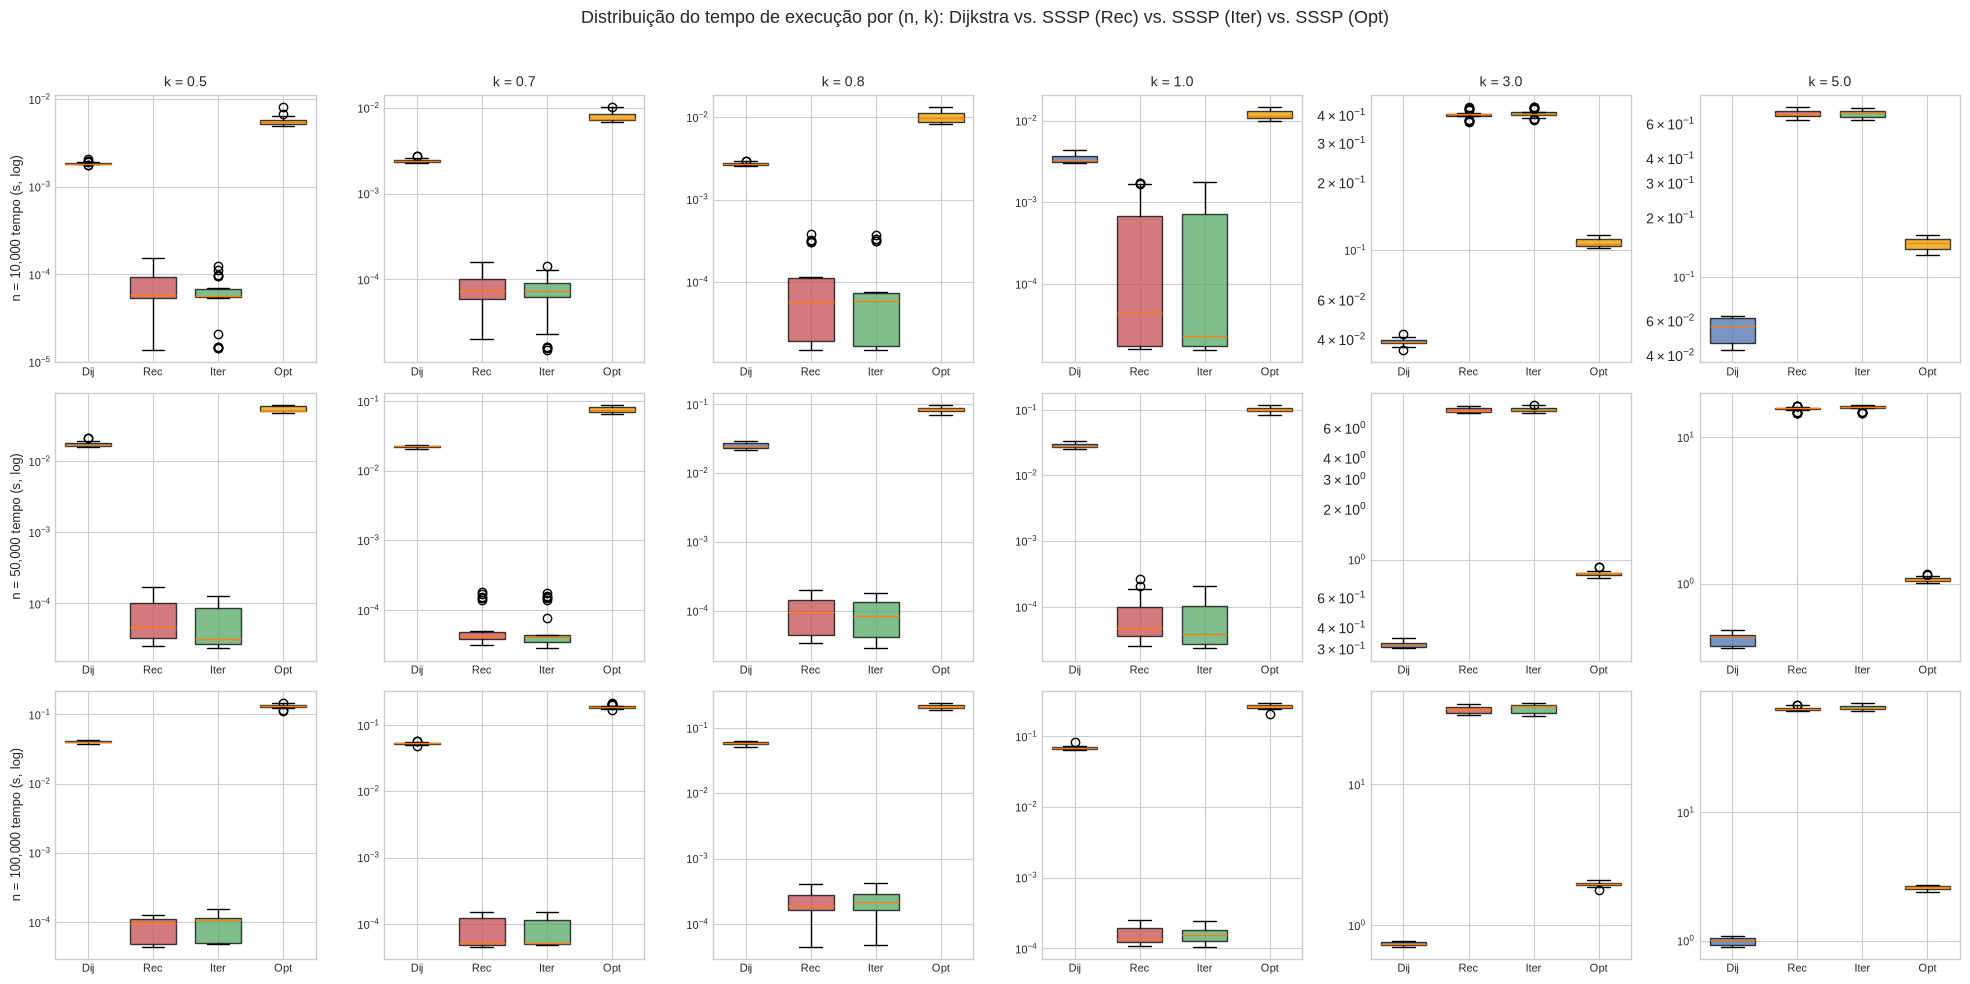

In [6]:
df = random_test

n_vals = sorted(df['num_vertices'].unique())
k_vals = sorted(df['avg_degree_k'].unique())
algoritmos = ['dijkstra', 'sssp_duan_et_al', 'sssp_duan_et_al_iter', 'sssp_duan_et_al_opt']
colors = {
    'dijkstra': '#4C72B0', 
    'sssp_duan_et_al': '#C44E52', 
    'sssp_duan_et_al_iter': '#55A868',
    'sssp_duan_et_al_opt': '#E69F00'
}
labels_map = {
    'dijkstra': 'Dijkstra', 
    'sssp_duan_et_al': 'SSSP (Duan et al.)', 
    'sssp_duan_et_al_iter': 'SSSP (Iterativo)',
    'sssp_duan_et_al_opt': 'SSSP (Otimizado)'
}

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(len(n_vals), len(k_vals), figsize=(3.3*len(k_vals), 3.2*len(n_vals)), sharex=False)

for i, n in enumerate(n_vals):
    for j, k in enumerate(k_vals):
        ax = axes[i, j]
        sub = df[(df['num_vertices'] == n) & (df['avg_degree_k'] == k)]

        data = [sub[sub['algorithm'] == algo]['execution_time'].values
                for algo in algoritmos]
        bp = ax.boxplot(data, patch_artist=True, widths=0.7,
                         tick_labels=['Dij', 'Rec', 'Iter', 'Opt'])
        for patch, algo in zip(bp['boxes'], algoritmos):
            patch.set_facecolor(colors[algo])
            patch.set_alpha(0.75)

        ax.set_yscale('log')
        if i == 0:
            ax.set_title(f'k = {k}', fontsize=10)
        if j == 0:
            ax.set_ylabel(f'n = {n:,} tempo (s, log)', fontsize=9)
        ax.tick_params(axis='both', labelsize=8)

fig.suptitle('Distribuição do tempo de execução por (n, k): Dijkstra vs. SSSP (Rec) vs. SSSP (Iter) vs. SSSP (Opt)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

Nota: todos os casos onde o BMSSP é aparentemente menor, são em situações cuja conectividade do grafo é baixíssima

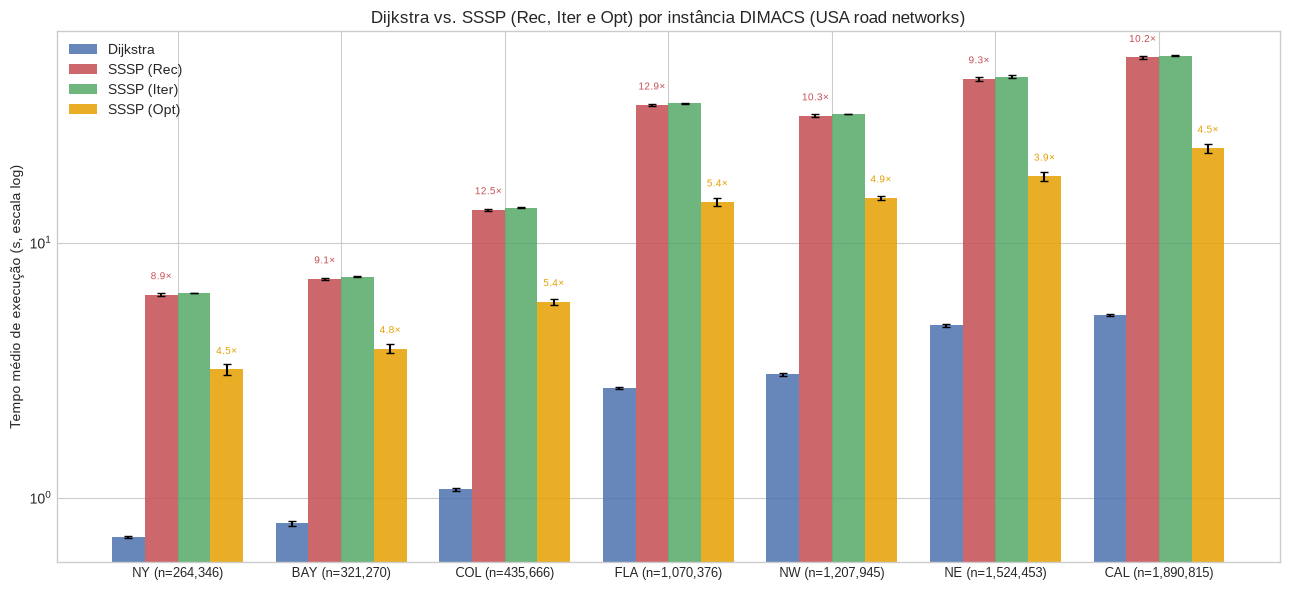

In [7]:
df = dimacs_test

agg = (df.groupby(['arquivo', 'num_vertices', 'algorithm'])['execution_time']
         .agg(['mean', 'std'])
         .reset_index()
         .sort_values('num_vertices'))

instancias = agg['arquivo'].unique()
algoritmos = ['dijkstra', 'sssp_duan_et_al', 'sssp_duan_et_al_iter', 'sssp_duan_et_al_opt']
colors = {
    'dijkstra': '#4C72B0', 
    'sssp_duan_et_al': '#C44E52', 
    'sssp_duan_et_al_iter': '#55A868',
    'sssp_duan_et_al_opt': '#E69F00'
}
labels_map = {
    'dijkstra': 'Dijkstra', 
    'sssp_duan_et_al': 'SSSP (Rec)', 
    'sssp_duan_et_al_iter': 'SSSP (Iter)',
    'sssp_duan_et_al_opt': 'SSSP (Opt)'
}

x = np.arange(len(instancias))
width = 0.20

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(13, 6))

for i, algo in enumerate(algoritmos):
    sub = agg[agg['algorithm'] == algo].set_index('arquivo').loc[instancias]
    offset = (i - 1.5) * width
    ax.bar(x + offset, sub['mean'], width, yerr=sub['std'], capsize=3,
           label=labels_map[algo], color=colors[algo], alpha=0.85)

ax.set_yscale('log')
ax.set_xticks(x)
nomes = [f"{arq.split('.')[1]} (n={n:,})"
         for arq, n in agg.drop_duplicates('arquivo')[['arquivo', 'num_vertices']].sort_values('num_vertices').values]
ax.set_xticklabels(nomes, fontsize=9)
ax.set_ylabel('Tempo médio de execução (s, escala log)')
ax.set_title('Dijkstra vs. SSSP (Rec, Iter e Opt) por instância DIMACS (USA road networks)')
ax.legend()

# Anota o fator de desvantagem em relação ao Dijkstra
piv = agg.pivot(index='arquivo', columns='algorithm', values='mean').loc[instancias]
for xi, arq in zip(x, instancias):
    ratio_rec = piv.loc[arq, 'sssp_duan_et_al'] / piv.loc[arq, 'dijkstra']
    ratio_opt = piv.loc[arq, 'sssp_duan_et_al_opt'] / piv.loc[arq, 'dijkstra']
    ax.text(xi - 0.5*width, piv.loc[arq, 'sssp_duan_et_al'] * 1.15, f'{ratio_rec:.1f}×',
            ha='center', fontsize=7.5, color='#C44E52')
    ax.text(xi + 1.5*width, piv.loc[arq, 'sssp_duan_et_al_opt'] * 1.15, f'{ratio_opt:.1f}×',
            ha='center', fontsize=7.5, color='#E69F00')

plt.tight_layout()
plt.show()

#### 3. Impacto da Otimização da Fila em Lote (Speedup do BMSSP Opt vs Rec/Iter)

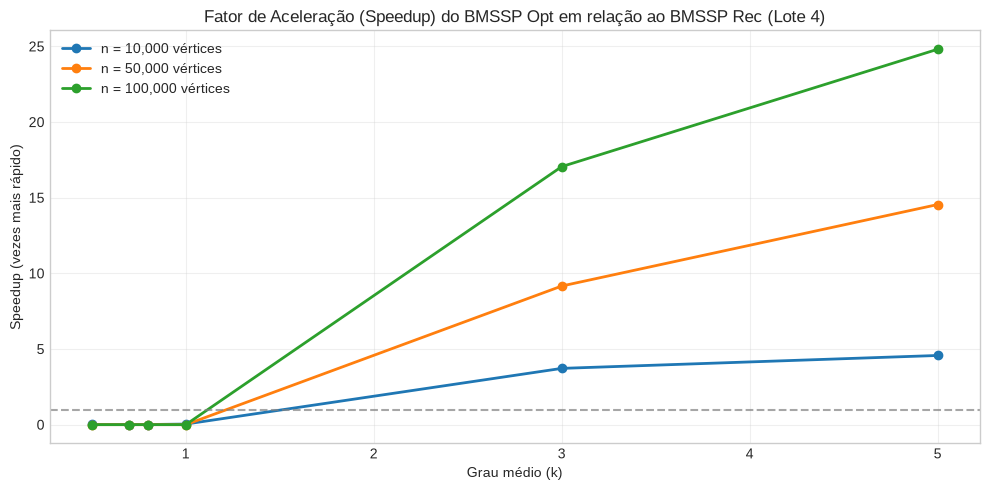

Speedup médio por número de vértices (Grafos Aleatórios):
 num_vertices  speedup_opt_vs_rec  speedup_opt_vs_iter
        10000            1.394401             1.401524
        50000            3.952664             4.005383
       100000            6.978162             7.121395
Speedup médio nas redes viárias DIMACS (sem transformação):
algorithm             speedup_opt_vs_rec  speedup_opt_vs_iter
arquivo                                                      
USA-road-d.BAY.gr.gz            1.877157             1.910734
USA-road-d.CAL.gr.gz            2.267330             2.303811
USA-road-d.COL.gr.gz            2.294520             2.337709
USA-road-d.FLA.gr.gz            2.400093             2.432672
USA-road-d.NE.gr.gz             2.408153             2.456976
USA-road-d.NW.gr.gz             2.097632             2.134889
USA-road-d.NY.gr.gz             1.963399             1.995259


In [8]:
# Comparação de Speedup do algoritmo otimizado (Opt) em relação ao original (Rec)
r = random_test.copy()
piv_r = r.pivot_table(index=['num_vertices', 'avg_degree_k'], columns='algorithm', values='execution_time', aggfunc='mean')
piv_r['speedup_opt_vs_rec'] = piv_r['sssp_duan_et_al'] / piv_r['sssp_duan_et_al_opt']
piv_r['speedup_opt_vs_iter'] = piv_r['sssp_duan_et_al_iter'] / piv_r['sssp_duan_et_al_opt']

fig, ax = plt.subplots(figsize=(10, 5))
for n in sorted(r['num_vertices'].unique()):
    sub = piv_r.loc[n].reset_index()
    ax.plot(sub['avg_degree_k'], sub['speedup_opt_vs_rec'], marker='o', linewidth=2, label=f'n = {n:,} vértices')

ax.set_title('Fator de Aceleração (Speedup) do BMSSP Opt em relação ao BMSSP Rec (Lote 4)')
ax.set_xlabel('Grau médio (k)')
ax.set_ylabel('Speedup (vezes mais rápido)')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.7)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Resumo médio do speedup por número de vértices
resumo_speedup = piv_r.groupby('num_vertices')[['speedup_opt_vs_rec', 'speedup_opt_vs_iter']].mean().reset_index()
print("Speedup médio por número de vértices (Grafos Aleatórios):")
print(resumo_speedup.to_string(index=False))

# Speedup nas instâncias DIMACS
piv_d = dimacs_test.pivot_table(index='arquivo', columns='algorithm', values='execution_time', aggfunc='mean')
piv_d['speedup_opt_vs_rec'] = piv_d['sssp_duan_et_al'] / piv_d['sssp_duan_et_al_opt']
piv_d['speedup_opt_vs_iter'] = piv_d['sssp_duan_et_al_iter'] / piv_d['sssp_duan_et_al_opt']
print("Speedup médio nas redes viárias DIMACS (sem transformação):")
print(piv_d[['speedup_opt_vs_rec', 'speedup_opt_vs_iter']])

#### 4. Transformação para grau constante melhora ou piora a performance?

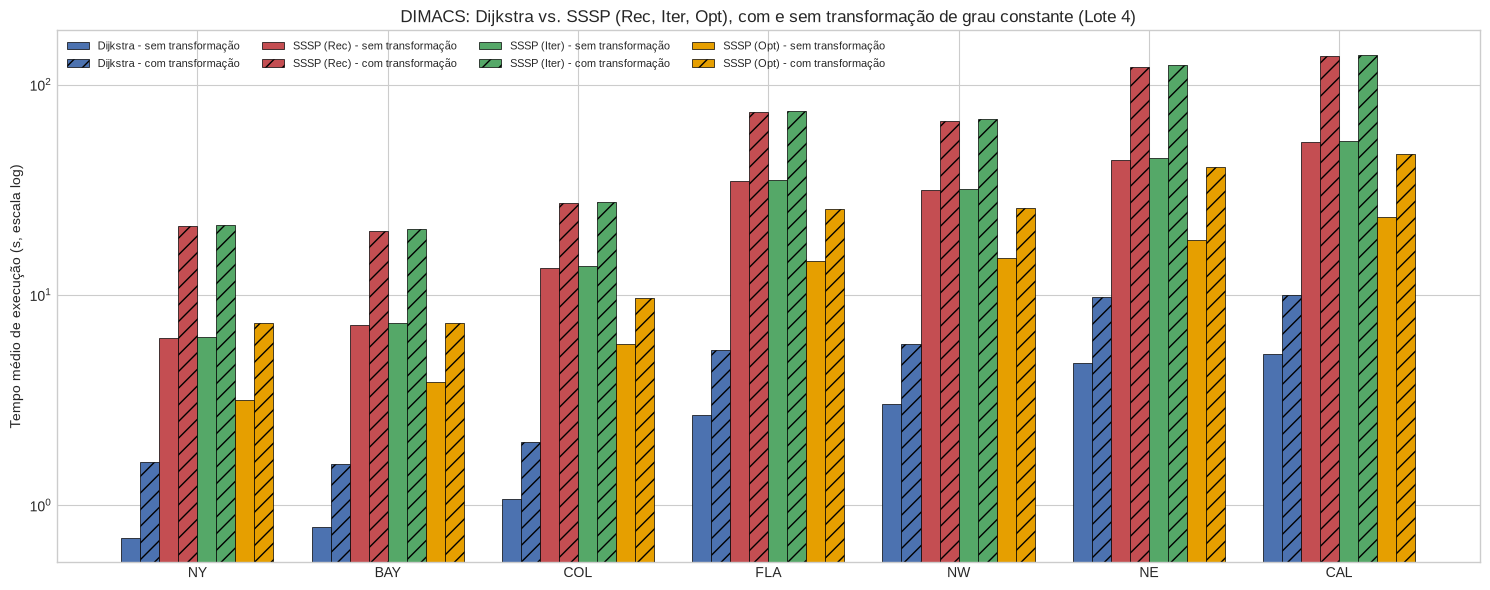

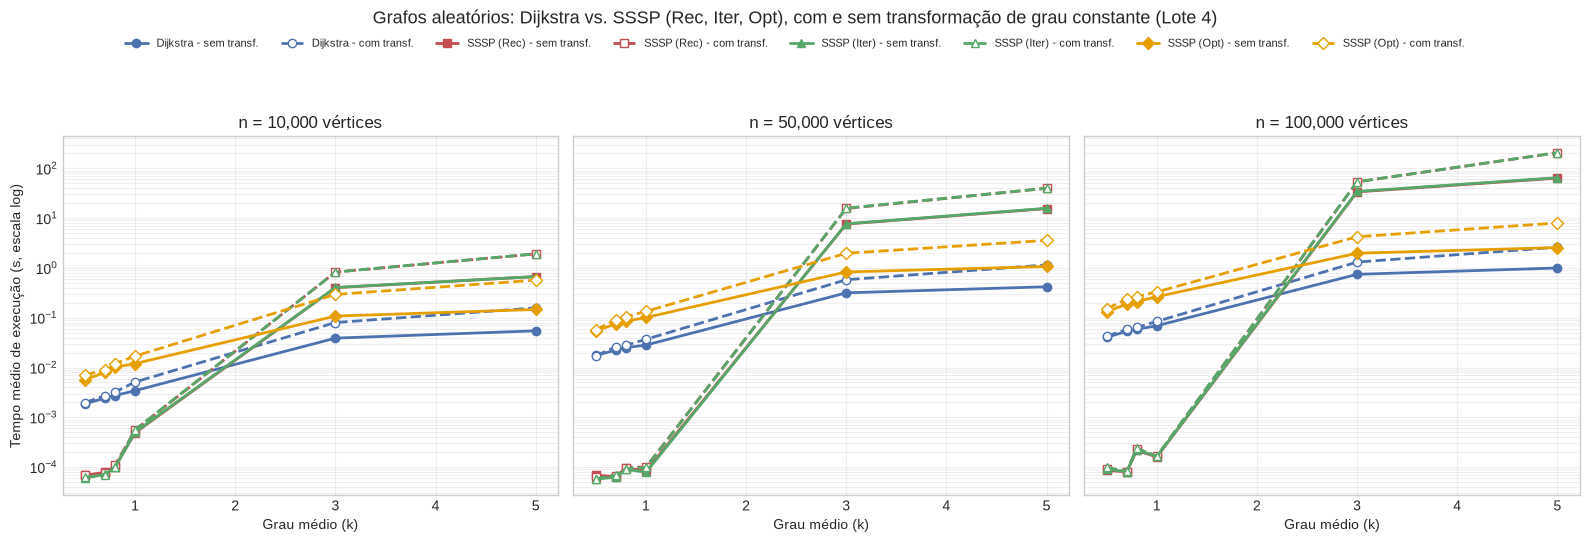

In [9]:
base = './../data/lote4-tcc2/results/'

# --- DIMACS: original vs. transformado, por instância ---
orig_d = pd.read_csv(base + 'dimacs-results-2026-10-25_03-00-21.csv')
trans_d = pd.read_csv(base + 'dimacs-results-2026-10-25_02-14-33.csv')

orig_d['condicao'] = 'sem transformação'
trans_d['condicao'] = 'com transformação'
d = pd.concat([orig_d, trans_d])

agg_d = (d.groupby(['arquivo', 'num_vertices', 'algorithm', 'condicao'])['execution_time']
           .mean().reset_index().sort_values('num_vertices'))

instancias = agg_d.drop_duplicates('arquivo').sort_values('num_vertices')['arquivo'].tolist()
combinacoes = [
    ('dijkstra', 'sem transformação'), ('dijkstra', 'com transformação'),
    ('sssp_duan_et_al', 'sem transformação'), ('sssp_duan_et_al', 'com transformação'),
    ('sssp_duan_et_al_iter', 'sem transformação'), ('sssp_duan_et_al_iter', 'com transformação'),
    ('sssp_duan_et_al_opt', 'sem transformação'), ('sssp_duan_et_al_opt', 'com transformação')
]
cores = {
    'dijkstra': '#4C72B0', 
    'sssp_duan_et_al': '#C44E52', 
    'sssp_duan_et_al_iter': '#55A868',
    'sssp_duan_et_al_opt': '#E69F00'
}
labels_base = {
    'dijkstra': 'Dijkstra', 
    'sssp_duan_et_al': 'SSSP (Rec)', 
    'sssp_duan_et_al_iter': 'SSSP (Iter)',
    'sssp_duan_et_al_opt': 'SSSP (Opt)'
}
hachuras = {'sem transformação': '', 'com transformação': '//'}

x = np.arange(len(instancias))
width = 0.10

fig, ax = plt.subplots(figsize=(15, 6))
for i, (algo, cond) in enumerate(combinacoes):
    vals = [agg_d[(agg_d['arquivo'] == inst) & (agg_d['algorithm'] == algo) & (agg_d['condicao'] == cond)]['execution_time'].values[0]
            for inst in instancias]
    ax.bar(x + (i - 3.5) * width, vals, width, color=cores[algo], hatch=hachuras[cond],
           edgecolor='black', linewidth=0.5,
           label=f"{labels_base[algo]} - {cond}")

ax.set_yscale('log')
ax.set_xticks(x)
ax.set_xticklabels([i.split('.')[1] for i in instancias])
ax.set_ylabel('Tempo médio de execução (s, escala log)')
ax.set_title('DIMACS: Dijkstra vs. SSSP (Rec, Iter, Opt), com e sem transformação de grau constante (Lote 4)')
ax.legend(fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

# --- Aleatórios: original vs. transformado, faceteado por num_vertices ---
orig_r = pd.read_csv(base + 'results-2026-10-25_00-27-26.csv')
trans_r = pd.read_csv(base + 'results-2026-10-24_22-36-20.csv')
orig_r['condicao'] = 'sem transformação'
trans_r['condicao'] = 'com transformação'
r = pd.concat([orig_r, trans_r])

agg_r = (r.groupby(['num_vertices', 'avg_degree_k', 'algorithm', 'condicao'])['execution_time']
           .mean().reset_index())

n_vals = sorted(agg_r['num_vertices'].unique())
estilos = {
    ('dijkstra', 'sem transformação'): dict(color='#4C72B0', linestyle='-', marker='o'),
    ('dijkstra', 'com transformação'): dict(color='#4C72B0', linestyle='--', marker='o', markerfacecolor='white'),
    ('sssp_duan_et_al', 'sem transformação'): dict(color='#C44E52', linestyle='-', marker='s'),
    ('sssp_duan_et_al', 'com transformação'): dict(color='#C44E52', linestyle='--', marker='s', markerfacecolor='white'),
    ('sssp_duan_et_al_iter', 'sem transformação'): dict(color='#55A868', linestyle='-', marker='^'),
    ('sssp_duan_et_al_iter', 'com transformação'): dict(color='#55A868', linestyle='--', marker='^', markerfacecolor='white'),
    ('sssp_duan_et_al_opt', 'sem transformação'): dict(color='#E69F00', linestyle='-', marker='D'),
    ('sssp_duan_et_al_opt', 'com transformação'): dict(color='#E69F00', linestyle='--', marker='D', markerfacecolor='white')
}
label_map = {
    ('dijkstra', 'sem transformação'): 'Dijkstra - sem transf.',
    ('dijkstra', 'com transformação'): 'Dijkstra - com transf.',
    ('sssp_duan_et_al', 'sem transformação'): 'SSSP (Rec) - sem transf.',
    ('sssp_duan_et_al', 'com transformação'): 'SSSP (Rec) - com transf.',
    ('sssp_duan_et_al_iter', 'sem transformação'): 'SSSP (Iter) - sem transf.',
    ('sssp_duan_et_al_iter', 'com transformação'): 'SSSP (Iter) - com transf.',
    ('sssp_duan_et_al_opt', 'sem transformação'): 'SSSP (Opt) - sem transf.',
    ('sssp_duan_et_al_opt', 'com transformação'): 'SSSP (Opt) - com transf.'
}

fig, axes = plt.subplots(1, len(n_vals), figsize=(16, 4.8), sharey=True)
for ax, n in zip(axes, n_vals):
    sub = agg_r[agg_r['num_vertices'] == n]
    for (algo, cond), estilo in estilos.items():
        s = sub[(sub['algorithm'] == algo) & (sub['condicao'] == cond)].sort_values('avg_degree_k')
        ax.plot(s['avg_degree_k'], s['execution_time'], label=label_map[(algo, cond)], linewidth=2, **estilo)
    ax.set_yscale('log')
    ax.set_title(f'n = {n:,} vértices')
    ax.set_xlabel('Grau médio (k)')
    ax.grid(True, which='both', alpha=0.3)

axes[0].set_ylabel('Tempo médio de execução (s, escala log)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=8, bbox_to_anchor=(0.5, 1.08), frameon=False, fontsize=8)
fig.suptitle('Grafos aleatórios: Dijkstra vs. SSSP (Rec, Iter, Opt), com e sem transformação de grau constante (Lote 4)', y=1.12, fontsize=13)
plt.tight_layout()
plt.show()